# Triangle plots for subluminal chains, constant $c_s^2$, without the quasi-static approximation

In [1]:
import numpy as np
import getdist
from getdist import plots
from matplotlib.lines import Line2D

import utils

In [2]:
indices = [48, 56, 57, 58, 59, 83, 113, 114, 115, 116]
chains = {}
for i in indices:
    chains[i] = utils.load_chain(i, burn_in=0.2, smooth_2D=0.3)

../chains/MCMC48/MCMC48.1.txt


../chains/MCMC48/MCMC48.2.txt


../chains/MCMC48/MCMC48.3.txt


../chains/MCMC48/MCMC48.4.txt


Removed no burn in


...

../chains/MCMC83/MCMC83.1.txt


../chains/MCMC83/MCMC83.2.txt


../chains/MCMC83/MCMC83.3.txt


../chains/MCMC83/MCMC83.4.txt


Removed no burn in


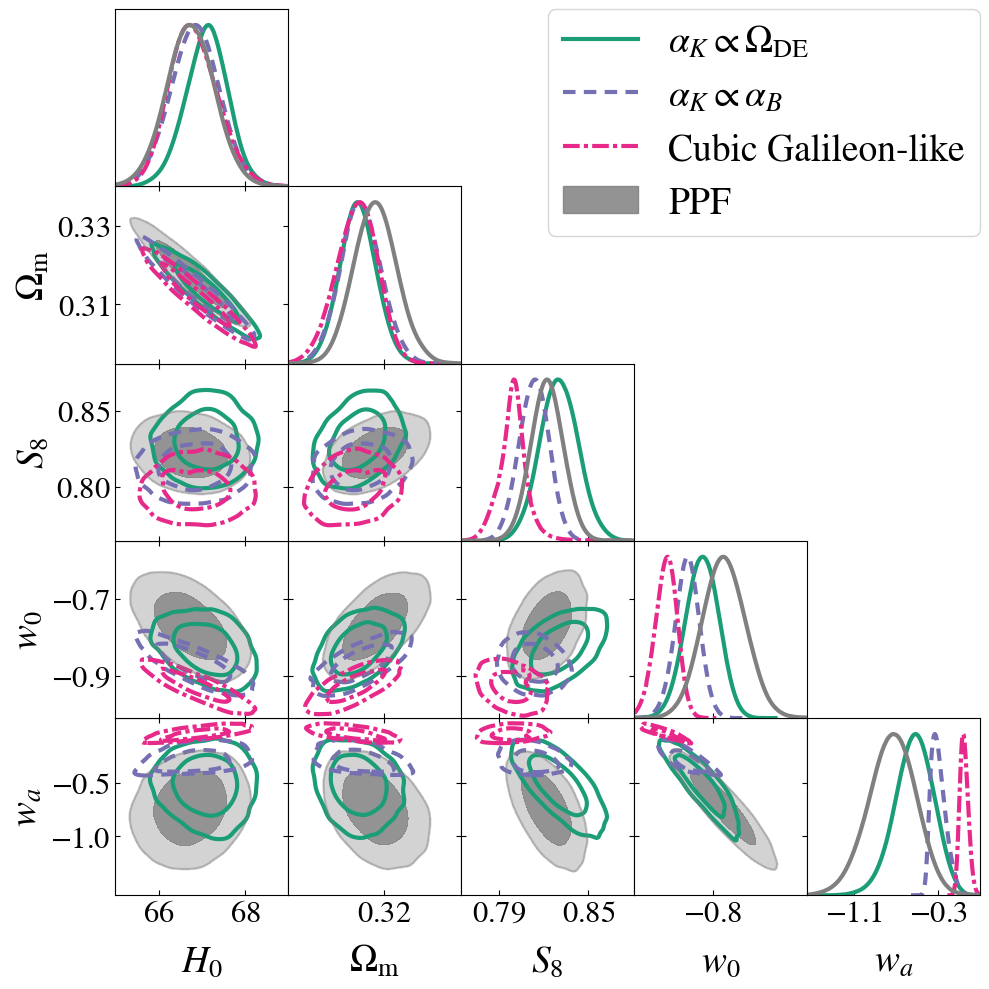

In [3]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=30
p.triangle_plot(
    [chains[113], chains[115], chains[116], chains[48]],
    ["H0", "omegam", "S8", "w", "wa"],
    filled=[False, False, False, True],
    contour_colors=[utils.colors[0], utils.colors[2], utils.colors[3], "gray"],
    contour_lws=3,
    contour_ls=["-", "--", "-.", "-"],
    legend_labels=["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1.01, -0.55], "wa": [-1.55, 0.1], "H0": [65, 69], "omegam": [0.295, 0.34]}
)
p.fig.savefig("plots/triangle_ds1_subluminal_mg_noqsa.pdf", bbox_inches="tight")

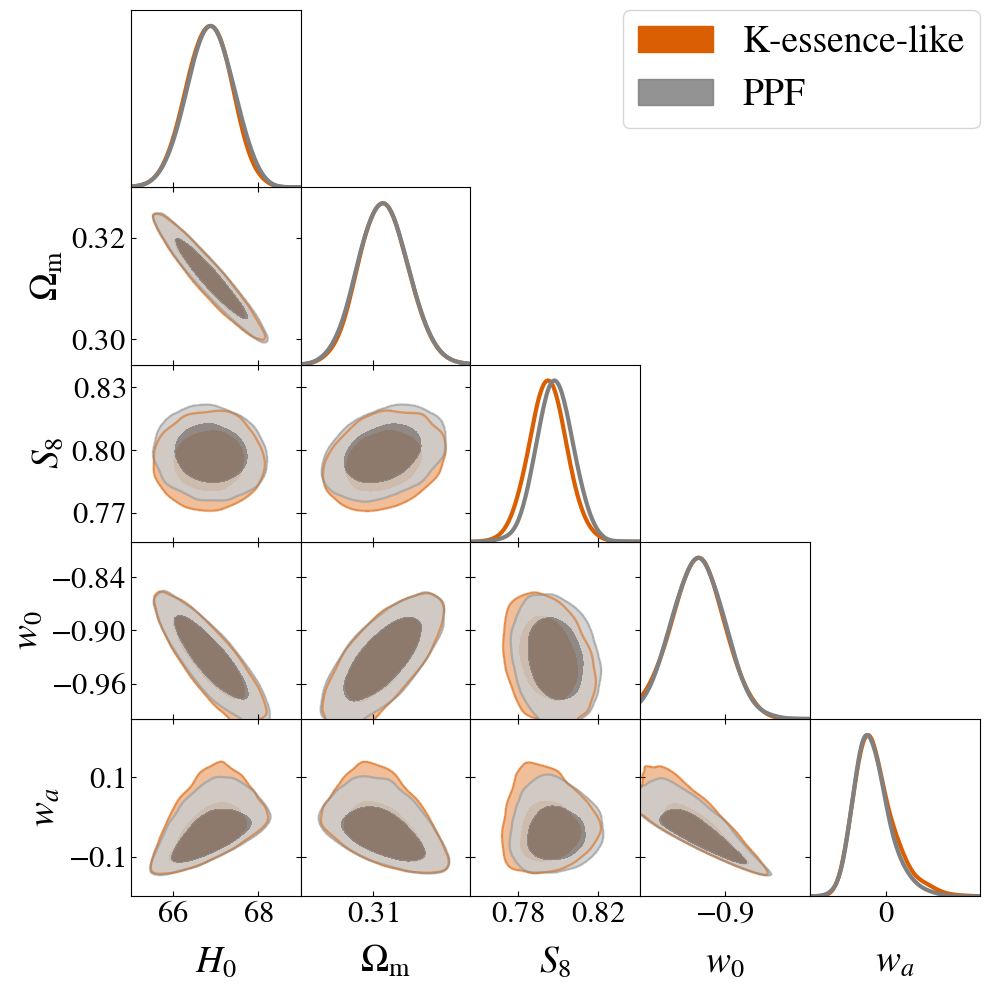

In [4]:
p = plots.get_subplot_plotter()
p.settings.axes_fontsize=25
p.settings.axes_labelsize=30
p.settings.legend_fontsize=30
p.triangle_plot(
    [chains[114], chains[83]],
    ["H0", "omegam", "S8", "w", "wa"],
    filled=[True, True],
    contour_colors=[utils.colors[1], "gray"],
    contour_lws=3,
    contour_ls='-',
    legend_labels=["K-essence-like", "PPF"],
    legend_loc="upper right",
    param_limits={"w": [-1, -0.8], "H0": [65, 69], "omegam": [0.295, 0.33]}
)
p.fig.savefig("plots/triangle_ds1_subluminal_mg_kessence_noqsa.pdf", bbox_inches="tight")

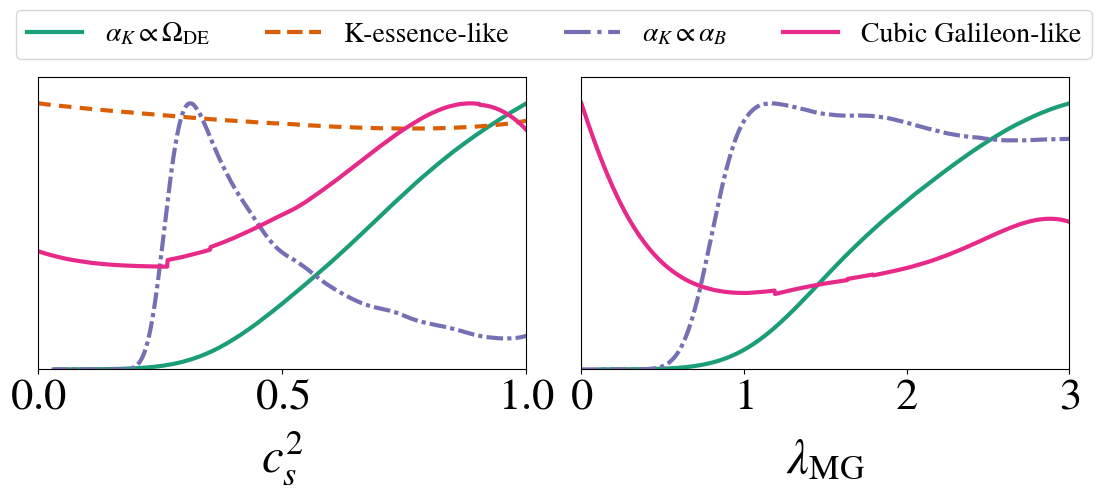

In [5]:
p = plots.get_subplot_plotter(width_inch=11, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.settings.legend_fontsize=30
labels = ["$\\alpha_K \\propto \\Omega_\\mathrm{DE}$", "K-essence-like", "$\\alpha_K \\propto \\alpha_B$", "Cubic Galileon-like"]
p.plots_1d(
    [chains[113], chains[114], chains[115], chains[116]],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors,
    lws=3,
    ls=["-", "--", "-.", "-"],
    nx=2,
    legend_labels=[],
)

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[0]),
    Line2D([], [], linewidth=3, linestyle="--", color=utils.colors[1]),
    Line2D([], [], linewidth=3, linestyle="-.", color=utils.colors[2]),
    Line2D([], [], linewidth=3, linestyle="-",  color=utils.colors[3]),
]

# place legend relative to the figure (x,y in figure coordinates)
p.fig.legend(handles, labels,
             loc="upper center",
             ncol=4,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.15),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds1_noqsa.pdf", bbox_inches="tight")

In [6]:
def latex_value(chain, param):
    if not chain.paramNames.hasParam(param): return "---"
    latex = chain.getInlineLatex(param)
    return f"${latex.split('=')[1]}$" if "=" in latex else f"${latex}$"

def print_table(columns, parameters):
    params = {name.name: label for name, label in zip(chains[113].paramNames.names, chains[113].paramNames.labels())}
    for param in parameters:
        print(f"${params[param]}$ & " + " & ".join(latex_value(chains[i], param) for i in columns) + r" \\ \hline")

In [7]:
# Getting numbers (same column order as the QSA table: PPF, Omega_DE, alpha_B, Cubic Galileon, K-essence, PPF w0waq)
print_table([48, 113, 115, 116, 114, 83], ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3177\pm 0.0060$ & $ 0.3131\pm 0.0048$ & $ 0.3138\pm 0.0053$ & $ 0.3128^{+0.0057}_{-0.0051}$ & $ 0.3121\pm 0.0051$ & $ 0.3121\pm 0.0058$ \\ \hline
$H_0$ & $ 66.74\pm 0.59$ & $ 67.11\pm 0.49$ & $ 66.84\pm 0.56$ & $ 66.80^{+0.51}_{-0.60}$ & $ 66.84\pm 0.54$ & $ 66.87\pm 0.59$ \\ \hline
$S_8$ & $ 0.822\pm 0.011$ & $ 0.830\pm 0.013$ & $ 0.813\pm 0.010$ & $ 0.7995\pm 0.0097$ & $ 0.7948\pm 0.0098$ & $ 0.798\pm 0.010$ \\ \hline
$w_0$ & $ -0.771\pm 0.061$ & $ -0.829\pm 0.044$ & $ -0.869\pm 0.033$ & $ -0.925^{+0.032}_{-0.027}$ & $ -0.931\pm 0.030$ & $ -0.930\pm 0.032$ \\ \hline
$w_a$ & $ -0.74^{+0.24}_{-0.22}$ & $ -0.53^{+0.20}_{-0.17}$ & $ -0.295^{+0.047}_{-0.088}$ & $ -0.052^{+0.036}_{-0.044}$ & $ -0.028^{+0.036}_{-0.063}$ & $ -0.035^{+0.036}_{-0.054}$ \\ \hline
$c_s^2$ & --- & $c_s^2 > 0.707$ & $ 0.479^{+0.075}_{-0.23}$ & $c_s^2 > 0.459$ & $ ---$ & $ ---$ \\ \hline
$\lambda_\mathrm{MG}$ & --- & $\lambda_\mathrm{MG} > 2.02$ & $ 1.85^{+0.58}_{-0.89}$ & $ ---$ & --- & -

In [8]:
def get_cov_w0wa(chain):
    return chain.getCov(pars=[chain.getParamNames().list().index("w"), chain.getParamNames().list().index("wa")])

cov_w0wa_gr = get_cov_w0wa(chains[48])
for i in [113, 115, 116]:
    print(i, np.sqrt((np.linalg.det(cov_w0wa_gr)/np.linalg.det(get_cov_w0wa(chains[i])))))

113 1.48260166187659
115 3.7815018565733807
116 12.340792457337201


## Comparison with the QSA chains

QSA chains: 56-59, nonlinear lensing, the exact QSA counterparts of 113-116. Dashed: QSA; solid: no QSA; gray: PPF.

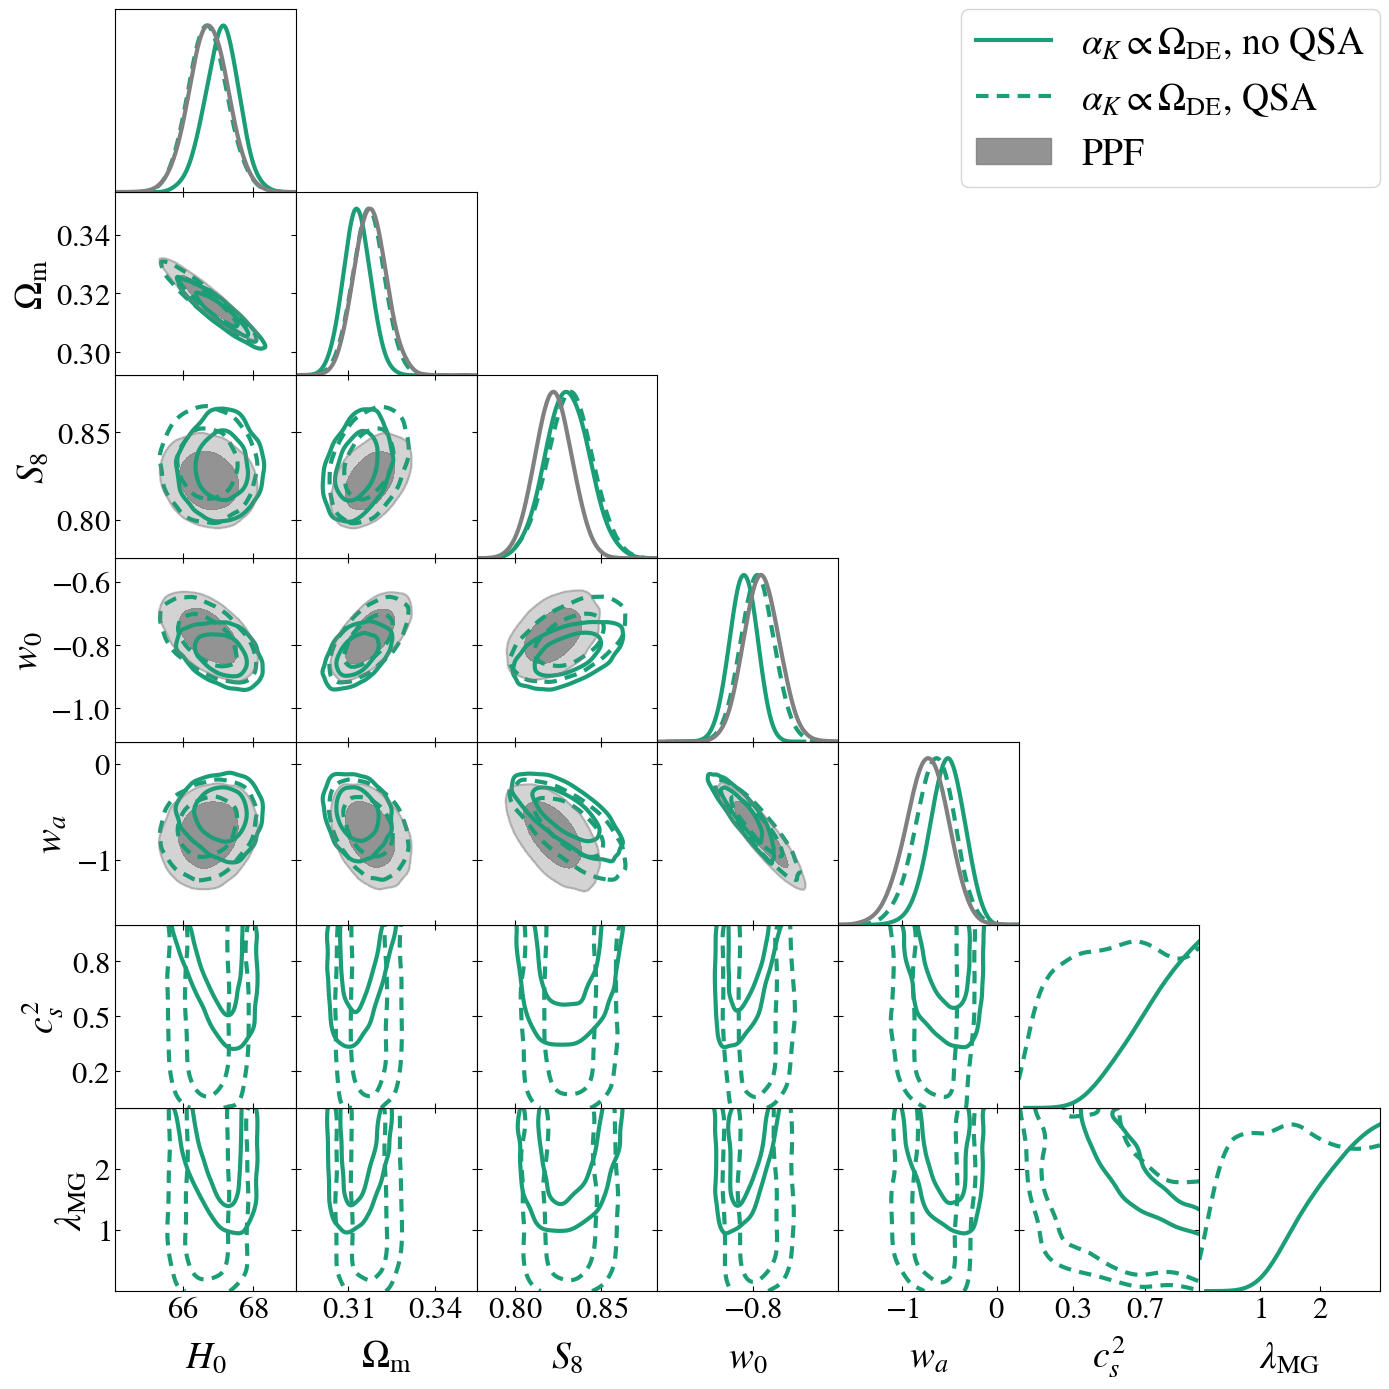

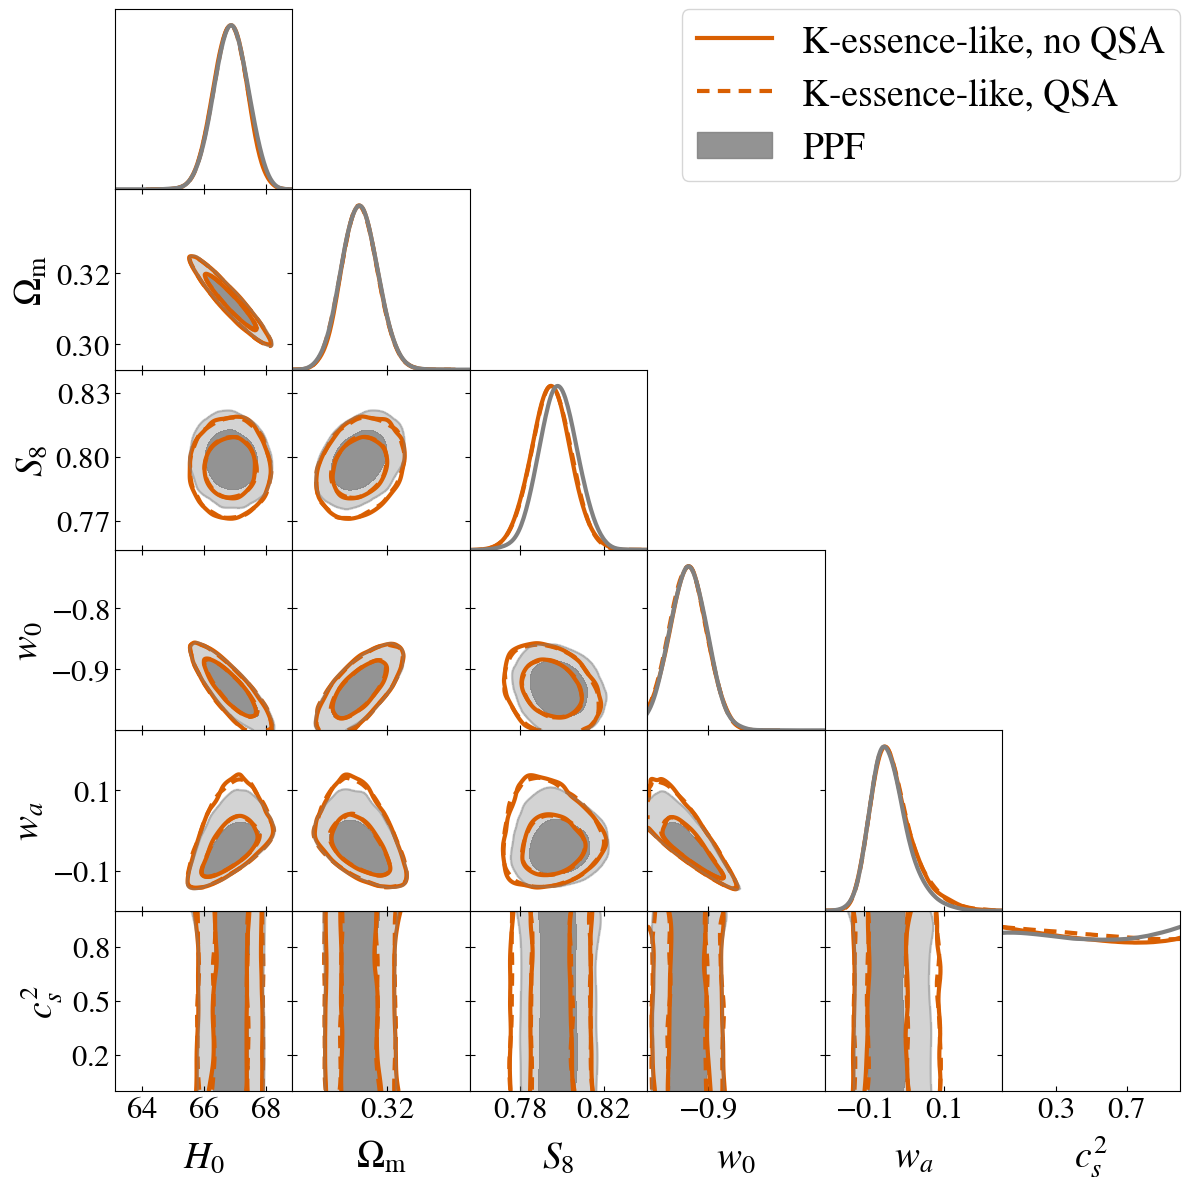

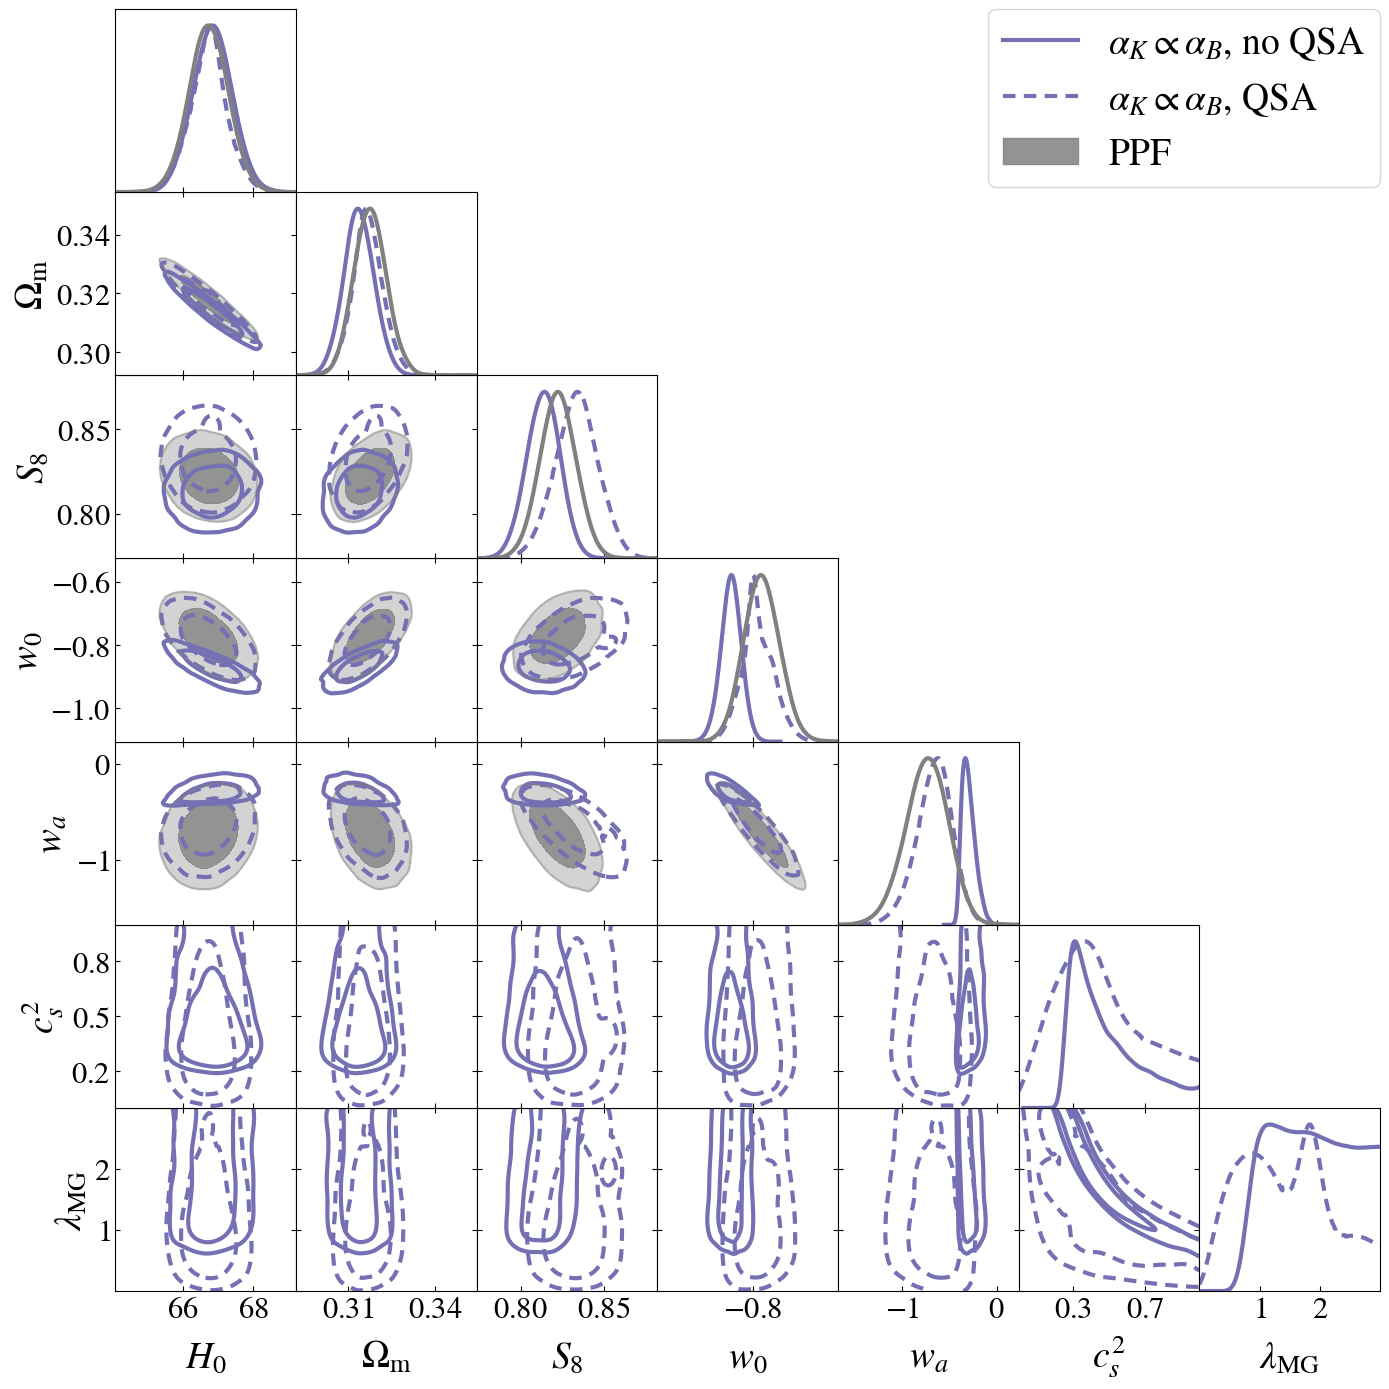

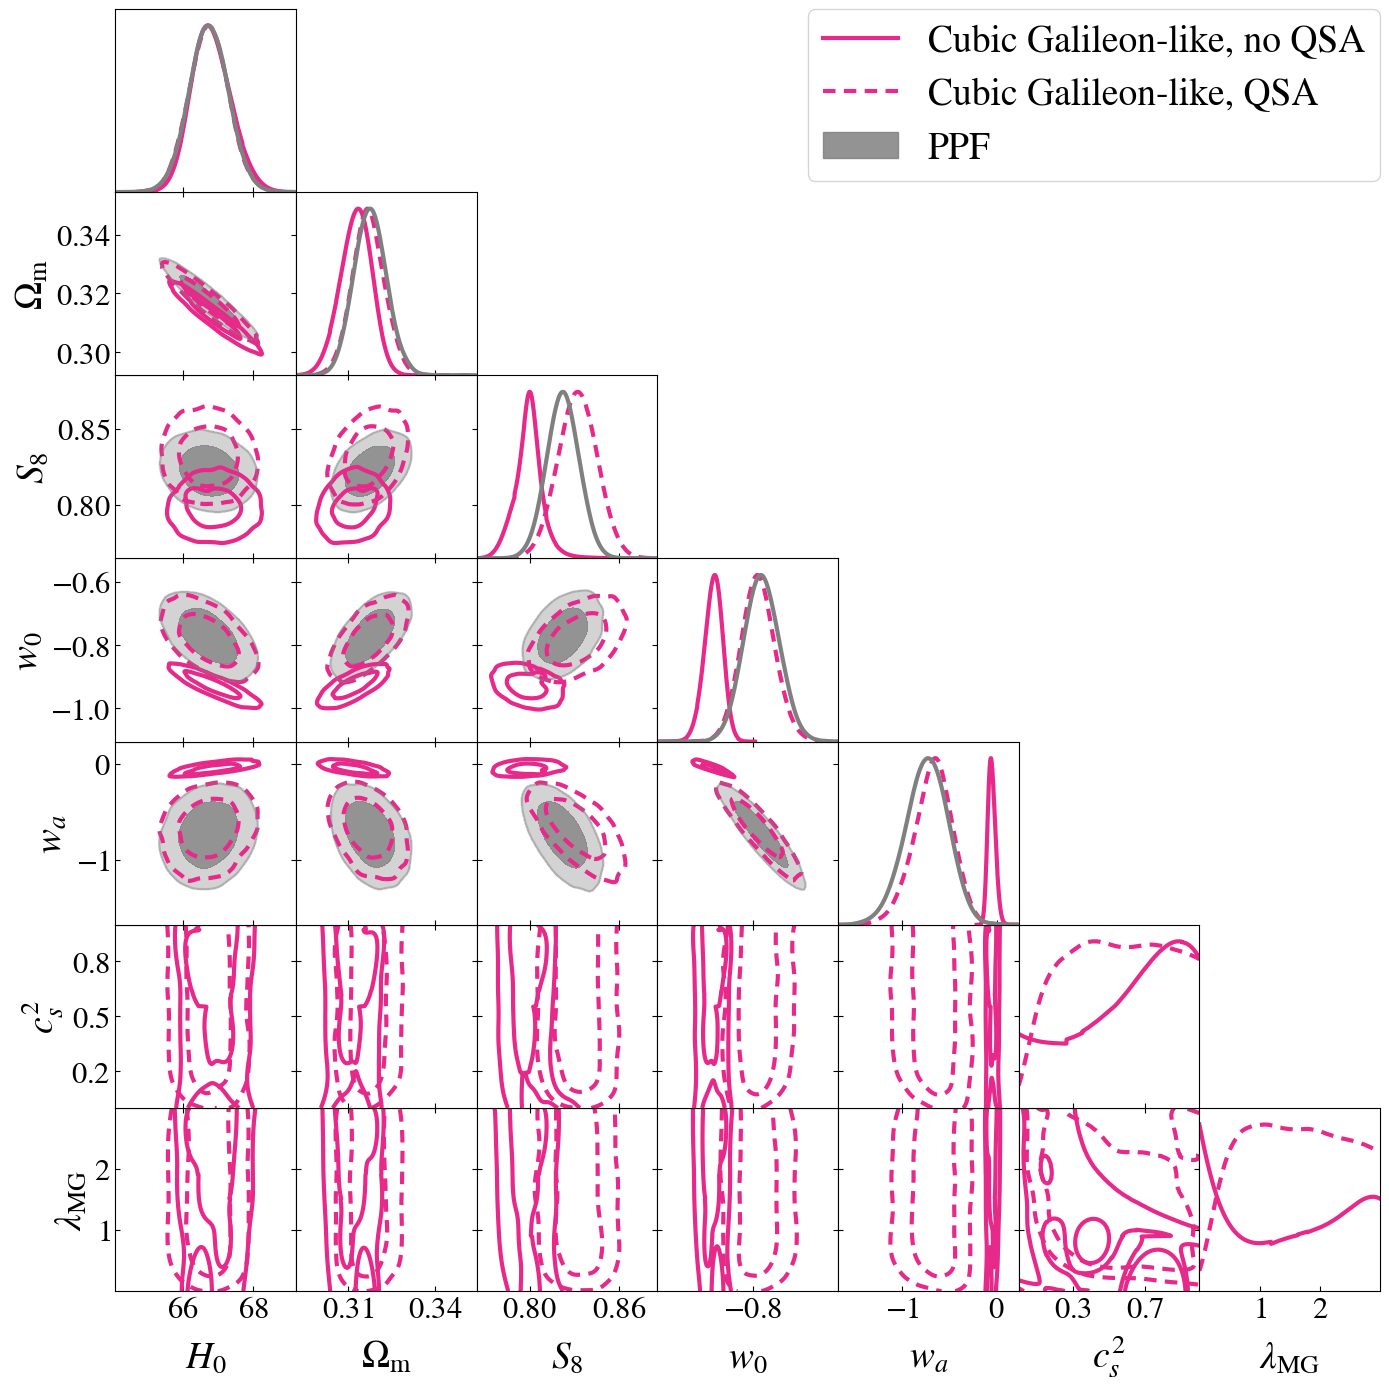

In [9]:
names = ["omega", "kessence", "prop", "cugal"]
noqsa_indices = [113, 114, 115, 116]
qsa_indices = [56, 57, 58, 59]
gr_indices = [48, 83, 48, 48]

for name, label, color, i_noqsa, i_qsa, i_gr in zip(names, labels, utils.colors, noqsa_indices, qsa_indices, gr_indices):
    params = ["H0", "omegam", "S8", "w", "wa", "cs2_0"]
    if chains[i_noqsa].paramNames.hasParam("alpha_K_0"): params.append("alpha_K_0")
    p = plots.get_subplot_plotter()
    p.settings.axes_fontsize=25
    p.settings.axes_labelsize=30
    p.settings.legend_fontsize=30
    p.triangle_plot(
        [chains[i_noqsa], chains[i_qsa], chains[i_gr]],
        params,
        filled=[False, False, True],
        contour_colors=[color, color, "gray"],
        contour_lws=3,
        contour_ls=["-", "--", "-"],
        legend_labels=[f"{label}, no QSA", f"{label}, QSA", "PPF"],
        legend_loc="upper right",
    )
    p.fig.savefig(f"plots/triangle_ds1_subluminal_qsa_vs_noqsa_{name}.pdf", bbox_inches="tight")

In [10]:
# Columns: for each model (Omega_DE, alpha_B, Cubic Galileon, K-essence), QSA then no QSA
columns = []
for i_qsa, i_noqsa in [(56, 113), (58, 115), (59, 116), (57, 114)]:
    columns += [i_qsa, i_noqsa]
print_table(columns, ["omegam", "H0", "S8", "w", "wa", "cs2_0", "alpha_K_0"])

$\Omega_\mathrm{m}$ & $ 0.3171\pm 0.0056$ & $ 0.3131\pm 0.0048$ & $ 0.3169\pm 0.0053$ & $ 0.3138\pm 0.0053$ & $ 0.3171\pm 0.0056$ & $ 0.3128^{+0.0057}_{-0.0051}$ & $ 0.3120\pm 0.0052$ & $ 0.3121\pm 0.0051$ \\ \hline
$H_0$ & $ 66.71\pm 0.56$ & $ 67.11\pm 0.49$ & $ 66.74\pm 0.53$ & $ 66.84\pm 0.56$ & $ 66.74\pm 0.56$ & $ 66.80^{+0.51}_{-0.60}$ & $ 66.86\pm 0.54$ & $ 66.84\pm 0.54$ \\ \hline
$S_8$ & $ 0.832\pm 0.013$ & $ 0.830\pm 0.013$ & $ 0.833\pm 0.013$ & $ 0.813\pm 0.010$ & $ 0.832\pm 0.013$ & $ 0.7995\pm 0.0097$ & $ 0.7950\pm 0.0097$ & $ 0.7948\pm 0.0098$ \\ \hline
$w_0$ & $ -0.784\pm 0.055$ & $ -0.829\pm 0.044$ & $ -0.783\pm 0.051$ & $ -0.869\pm 0.033$ & $ -0.782\pm 0.055$ & $ -0.925^{+0.032}_{-0.027}$ & $ -0.932\pm 0.030$ & $ -0.931\pm 0.030$ \\ \hline
$w_a$ & $ -0.66^{+0.22}_{-0.19}$ & $ -0.53^{+0.20}_{-0.17}$ & $ -0.66^{+0.20}_{-0.17}$ & $ -0.295^{+0.047}_{-0.088}$ & $ -0.67^{+0.22}_{-0.19}$ & $ -0.052^{+0.036}_{-0.044}$ & $ -0.028^{+0.036}_{-0.063}$ & $ -0.028^{+0.036}_{-0.063}$

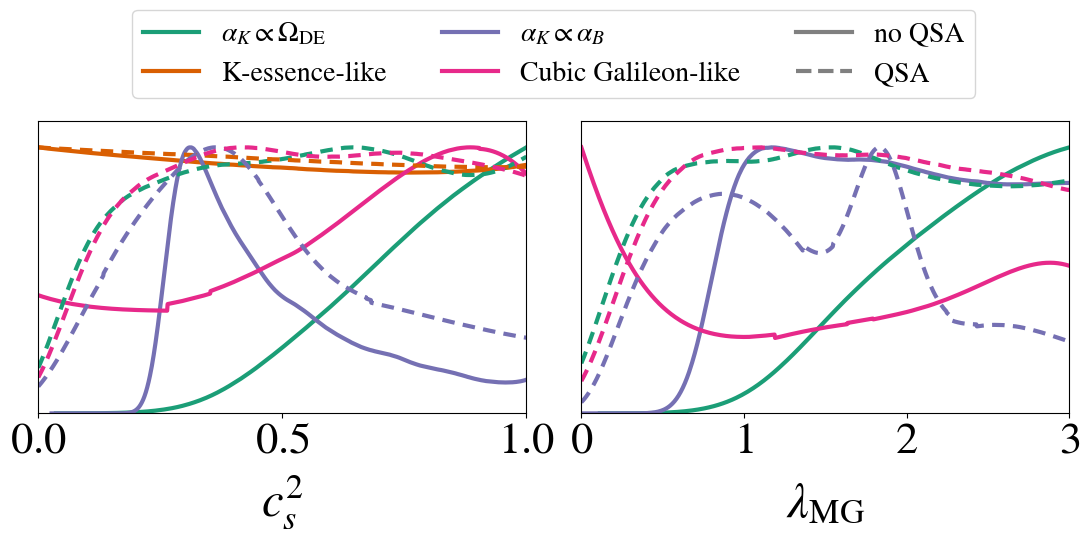

In [11]:
p = plots.get_subplot_plotter(width_inch=11, subplot_size_ratio=4/5)
p.settings.axes_fontsize=32
p.settings.axes_labelsize=35
p.plots_1d(
    [chains[i] for i in noqsa_indices] + [chains[i] for i in qsa_indices],
    ["cs2_0", "alpha_K_0"],
    colors=utils.colors[:4] + utils.colors[:4],
    lws=3,
    ls=["-"]*4 + ["--"]*4,
    nx=2,
    legend_labels=[],
)

handles = [Line2D([], [], linewidth=3, linestyle="-", color=color) for color in utils.colors[:4]]
handles += [Line2D([], [], linewidth=3, linestyle="-", color="gray"), Line2D([], [], linewidth=3, linestyle="--", color="gray")]
p.fig.legend(handles, labels + ["no QSA", "QSA"],
             loc="upper center",
             ncol=3,
             fontsize=20,
             bbox_to_anchor=(0.508, 1.25),
             bbox_transform=p.fig.transFigure,
             frameon=True)

p.fig.savefig("plots/lambda_mg_cs2_subluminal_ds1_qsa_vs_noqsa.pdf", bbox_inches="tight")

In [12]:
for i, chain in chains.items():
    try:
        print(i, chain.getGelmanRubin())
    except ValueError:
        print(i, "n/a (getdist could not compute R-1 after burn-in)")

48 0.016175718318237574
56 0.030335959583255186
57 0.032854743649448674


58 0.05425484401534733
59 0.06493190750052544
83 0.016126373551159156
113 0.044631616879625226


114 0.026102764650495887
115 0.02779777895708368
116 0.7644088676712668
